# Exercise 3 - The Ising Model

In this exercise, we will get to know the Ising model, an example of an undirected graphical model, and draw samples from it.

In the event of a persistent problem, do not hesitate to contact me at

- tobias.pretschold@uni-jena.de

### Submission

- Deadline of submission: Tue, 10 November 11:59 pm.
- Submission via Moodle

### Help
In case you cannot solve a task, you can use the saved values within the `help` directory. The checkpoints are named after the corresponding functions.

- Load arrays with [Numpy](https://numpy.org/doc/stable/reference/generated/numpy.load.html)
```
np.load('help/array_name.npy')
```
- Load functions with [Dill](https://dill.readthedocs.io/en/latest/dill.html)
```
import dill
with open('help/some_func.pkl', 'rb') as f:
    func = dill.load(f)
```

to continue working on the other tasks.

In [3]:
import itertools
import time
import numpy as np
import matplotlib.pyplot as plt

In [6]:
# helper functions, no need to change anything here

def plot_states(states: np.ndarray, probs: np.ndarray) -> None:
    '''
    Plots all configurations of a small grid (black = -1, white = +1), sorted by their probability.
    '''
    order = np.argsort(-probs)
    fig, axes = plt.subplots(2, len(probs) // 2, figsize=(1.2 * len(probs) // 2, 3))
    for ax, k in zip(axes.flat, order):
        ax.imshow(states[k], cmap='gray', vmin=-1, vmax=1)
        ax.set_title(f'{probs[k]:.3f}', fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
    plt.show()


def state_index(x: np.ndarray) -> int:
    '''
    Returns the index of the configuration x in the order of itertools.product([-1, 1], repeat=n).
    '''
    bits = (x.flatten() + 1) // 2
    return int(bits @ 2 ** np.arange(len(bits))[::-1])

# The Ising Model

The importance of the [Ising model](https://en.wikipedia.org/wiki/Ising_model) can hardly be overstated. It is a fundamental model of theoretical physics, originally invented as a model of a magnet. It is easy to write down, yet difficult to analyze. Its study has led to some of the central ideas of modern physics ([phase transitions](https://en.wikipedia.org/wiki/Phase_transition), the [renormalization group](https://en.wikipedia.org/wiki/Renormalization_group) and [universality](https://en.wikipedia.org/wiki/Universality_(dynamical_systems))). If you are curious, I recommend the book [Complexity and Criticality](https://www.math.utah.edu/~golden/resources/rylie/Complexity_and_Criticality.pdf) by Christensen and Moloney.


I decided to cover the Ising model in this course because of its importance for physics, but also because it is an instance of an undirected graphical model. I hope that the physics terminology helps you to gain some intuition, and much of it (energy, interactions, temperature, mean field, ...) carries over to graphical models in general.

## The Model

The Ising model describes a system of $n=L^2$ random variables $X_1,\ldots,X_n$, arranged on an $L\times L$ grid. Each variable represents a spin and takes values in $\{-1,+1\}$, corresponding to a spin pointing down or up, respectively.

<div>
<img src="images/ising_model.png" width="250"/>
</div>

An element $x=(x_1,\ldots,x_n)\in\mathcal{X}=\{-1,+1\}^n$ is called a configuration or state of the system. 
The model assigns an energy $E(x)$ to each configuration and defines a probability distribution over the state space through the Boltzmann distribution:

\begin{equation}
p(x) = \frac{1}{Z} \exp\Big(-\frac{E(x)}{T}\Big)\,, \qquad Z = \sum_{x \in \mathcal{X}} \exp\Big(-\frac{E(x)}{T}\Big)\,,
\end{equation}

where $T > 0$ is the temperature and the normalization constant $Z$ is called the partition function. Configurations with low energy are more probable. The energy is

\begin{equation}
E(x) = -h \sum_i x_i - \sum_{i \sim j} x_i x_j\,,
\end{equation}

and consists of two terms:

- **Field:** $h$ is an external (magnetic) field. For $h > 0$, every variable pointing up lowers the energy, for $h < 0$ every variable pointing down.
- **Interactions:** $i \sim j$ runs over all pairs of neighbors on the grid (up, down, left, right). Every pair of neighbors that agrees lowers the energy, every pair that disagrees raises it.

The temperature influences how much the energy matters. Suppose there is no field, $h = 0$, and the temperature is high. Then differences in energy hardly matter, all configurations are almost equally likely, and the variables point in random directions. If the temperature is low, however, small energy differences get amplified by the exponential.


### Task 1

Implement `energy`, which computes $E(x)$ for a configuration $x$ given as an $L \times L$ array.

As a sanity check, a $4 \times 4$ checkerboard pattern should have energy `24` for $h = 0.5$.

#### Task 1 — explanation

Add the field contribution and the interaction contribution:
\[
E(x)=-h\sum_{r,c}x_{r,c}
  -\sum_{r=0}^{L-2}\sum_{c=0}^{L-1}x_{r,c}x_{r+1,c}
  -\sum_{r=0}^{L-1}\sum_{c=0}^{L-2}x_{r,c}x_{r,c+1}.
\]
The two interaction sums pair each spin with its neighbor below and to the
right. This counts each undirected edge **once**, using **open boundaries**:
the last row/column does not wrap around. Equal spins contribute −1 per edge;
opposite spins contribute +1. A positive field favors +1 spins.

A 4 × 4 grid has \(2L(L-1)=24\) edges. All checkerboard neighbors disagree,
and its eight +1 spins cancel its eight −1 spins in the field term.
Therefore its energy is **24**, even when \(h=0.5\).

In [ ]:
def energy(x: np.ndarray, h: float) -> float:
    """Compute the Ising energy, counting each open-boundary edge once."""
    field = -h * np.sum(x)
    vertical = np.sum(x[:-1, :] * x[1:, :])
    horizontal = np.sum(x[:, :-1] * x[:, 1:])
    return float(field - vertical - horizontal)


checkerboard = 2 * (np.indices((4, 4)).sum(axis=0) % 2) - 1
checkerboard_energy = energy(checkerboard, h=0.5)
print(f'Checkerboard energy: {checkerboard_energy:g}')
assert (checkerboard_energy == 24)

Checkerboard energy: 24


## The Full Distribution

For a small grid, we can compute $p(x)$ for all $2^n$ configurations, just like the probability tensor in Exercise 1.

### Task 2

Implement `full_distribution`, which returns all configurations of an $L \times L$ grid as an array of shape $(2^n, L, L)$, in the order of `itertools.product([-1, 1], repeat=n)`, together with their probabilities.

As a sanity check, for $L = 2$, $T = 1$ and $h = 0$, the probability that all variables are $+1$ should be `0.45035742`.

#### Task 2 — explanation

There are \(n=L^2\) binary spins, hence \(2^{L^2}\) configurations.
Enumerate them in the requested order, reshape each into a grid, compute
its energy, then normalize its Boltzmann weight:
\[
p_k=\frac{\exp(-E_k/T)}{\sum_j\exp(-E_j/T)}.
\]
For numerical stability we use \(\exp(-(E_k-E_{\min})/T)\).
This multiplies every weight by the same constant, so the probabilities
are unchanged, while all exponential arguments are nonpositive.

For a 2 × 2 grid with zero field, two states have energy −4, twelve have
energy 0, and two have energy +4. Thus, at \(T=1\),
\[
p(\text{all }+1)=\frac{e^4}{2e^4+12+2e^{-4}}
\approx \mathbf{0.45035742}.
\]

In [4]:
def full_distribution(L: int, T: float, h: float) -> tuple:
    """Return all grids in product order and their Boltzmann probabilities."""
    if not isinstance(L, (int, np.integer)) or L < 1:
        raise ValueError('L must be a positive integer.')
    if not np.isfinite(T) or T <= 0:
        raise ValueError('T must be finite and positive.')
    states = np.array(list(itertools.product([-1, 1], repeat=L * L)),
                      dtype=np.int8).reshape(-1, L, L)
    energies = np.array([energy(x, h) for x in states])
    weights = np.exp(-(energies - energies.min()) / T)
    return states, weights / weights.sum()


states_check, probs_check = full_distribution(2, T=1.0, h=0.0)
p_all_up = probs_check[state_index(np.ones((2, 2), dtype=int))]
print(f'p(all +1): {p_all_up:.8f}')
assert np.isclose(probs_check.sum(), 1)
assert np.isclose(p_all_up, 0.45035742)

p(all +1): 0.45035742


The cell below shows all 16 configurations of a $2 \times 2$ grid, sorted by their probability. Play with $T$ and $h$: what happens for small and for large temperatures, and for $h \neq 0$?

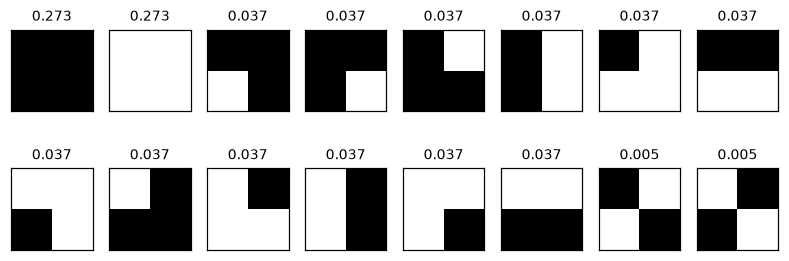

In [5]:
T, h = 2.0, 0.0

states, probs = full_distribution(2, T, h)
plot_states(states, probs)

#### How temperature and field change the distribution

- **Small \(T\), \(h=0\):** the two fully aligned grids dominate equally.
  As \(T\to0^+\), each has probability 1/2.
- **Large \(T\), fixed \(h\):** energy differences matter less. As
  \(T\to\infty\), each of the 16 grids has probability 1/16.
- **Nonzero \(h\):** positive fields favor +1 spins and negative fields
  favor −1 spins, breaking the symmetry between globally flipped grids.
  At low temperature a fixed positive field favors the all-+1 grid most.

Change `T, h` in the preceding cell to see these effects.

# Sampling

## Sampling from the Full Distribution

Given the vector `probs` with the probabilities of all configurations from Task 2, sampling is easy: we draw an index $k$ with probability `probs[k]`, and the sampled configuration is `states[k]`.

### Task 3

Implement `sample_from_probs`, which draws `n_samples` indices according to the probabilities `probs`, e.g. with [rng.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html).

Draw 10,000 samples for $L = 2$, $T = 2$ and $h = 0.5$, and check that the relative frequencies of the configurations match their probabilities.

#### Task 3 — explanation

Treat the configuration index as a categorical random variable: index
\(k\) has probability `probs[k]`. `rng.choice` draws independent indices
with replacement; `states[indices]` gives the actual grids if needed.
`np.bincount(..., minlength=len(probs))` counts every state, including
those never drawn. Divide by 10,000 to obtain relative frequencies.

The frequencies should be close, not identical, to the exact probabilities.
Each frequency has standard deviation \(\sqrt{p_k(1-p_k)/N}\), at most
0.005 for \(N=10{,}000\). We print all states and plot both distributions.
A fixed seed makes this demonstration reproducible.

Index   Exact probability   Sample frequency
    0             0.07531            0.07620
    1             0.01680            0.01420
    2             0.01680            0.01720
    3             0.02770            0.02860
    4             0.01680            0.01740
    5             0.02770            0.03120
    6             0.00375            0.00320
    7             0.04568            0.04610
    8             0.01680            0.01770
    9             0.00375            0.00420
   10             0.02770            0.02750
   11             0.04568            0.04510
   12             0.02770            0.02780
   13             0.04568            0.04550
   14             0.04568            0.04560
   15             0.55646            0.55250
Maximum absolute error: 0.00396
Total variation distance: 0.00814


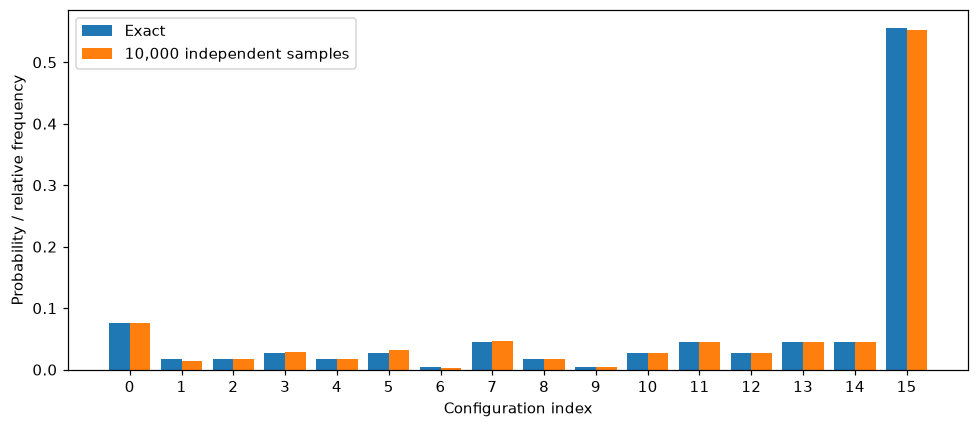

In [6]:
def sample_from_probs(probs: np.ndarray, n_samples: int,
                      rng: np.random.Generator) -> np.ndarray:
    """Draw independent configuration indices with replacement."""
    return rng.choice(len(probs), size=n_samples, replace=True, p=probs)


rng = np.random.default_rng(42)
states_exact, probs_exact = full_distribution(2, T=2.0, h=0.5)
n_samples = 10_000
indices = sample_from_probs(probs_exact, n_samples, rng)
frequencies = np.bincount(indices, minlength=len(probs_exact)) / n_samples

print('Index   Exact probability   Sample frequency')
for k, (p, f) in enumerate(zip(probs_exact, frequencies)):
    print(f'{k:5d}   {p:17.5f}   {f:16.5f}')
print(f'Maximum absolute error: {np.max(np.abs(frequencies - probs_exact)):.5f}')
print(f'Total variation distance: {0.5 * np.abs(frequencies - probs_exact).sum():.5f}')

positions = np.arange(len(probs_exact))
plt.figure(figsize=(9, 4))
plt.bar(positions - 0.2, probs_exact, width=0.4, label='Exact')
plt.bar(positions + 0.2, frequencies, width=0.4, label='10,000 independent samples')
plt.xlabel('Configuration index')
plt.ylabel('Probability / relative frequency')
plt.xticks(positions)
plt.legend()
plt.tight_layout()
plt.show()

This sampler needs the probabilities of all configurations. The cell below measures how long it takes to compute them for growing grids. How long would it take for a $10 \times 10$ grid?

In [7]:
timings = {}
for L in [2, 3, 4]:
    start = time.perf_counter()
    full_distribution(L, 2.0, 0.0)
    timings[L] = time.perf_counter() - start
    print(f'L = {L}: {2 ** (L * L)} configurations, {timings[L]:.3f} s')

# Optimistic extrapolation: assume the same time per state as for L = 4.
seconds_estimate = timings[4] * 2 ** (100 - 16)
years_estimate = seconds_estimate / (365.25 * 24 * 60 * 60)
print(f'10 x 10: {2 ** 100:.3e} configurations')
print(f'Optimistic time extrapolation: {years_estimate:.3e} years')

L = 2: 16 configurations, 0.000 s
L = 3: 512 configurations, 0.003 s
L = 4: 65536 configurations, 0.454 s
10 x 10: 1.268e+30 configurations
Optimistic time extrapolation: 2.785e+17 years


#### Why exact enumeration does not scale

The state counts are 16, 512 and 65,536 for \(L=2,3,4\), but
\(2^{100}\approx1.27\times10^{30}\) for \(L=10\).
Relative to the measured 4 × 4 calculation, there are
\(2^{84}\approx1.93\times10^{25}\) times as many states.
The code prints the resulting time estimate using this machine's timing.
Even processing **one billion states per second** would take about
**40 trillion years**.

The implementation actually needs \(O(L^2 2^{L^2})\) work and state storage,
so constant time per state is optimistic. Float64 probabilities alone
would require about \(10^{31}\) bytes for a 10 × 10 grid; materializing
the grids requires still more. This calculation is infeasible.

## Gibbs Sampling

Instead of sampling all variables at once, Gibbs sampling updates one variable at a time, drawing it from its conditional distribution given all other variables $X_{-i} = (X_j)_{j \neq i}$. This conditional is easy to compute. By definition,

\begin{equation}
p(X_i = x_i \mid X_{-i} = x_{-i}) = \frac{p(x)}{p(X_{-i} = x_{-i})} \propto p(x) \propto \exp\Big(-\frac{E(x)}{T}\Big)\,,
\end{equation}

where $\propto$ means equality up to factors that do not depend on $x_i$, like the denominator and $Z$. Next, we split the energy into the terms that contain $x_i$ and the rest,

\begin{equation}
E(x) = -x_i \Big(\sum_{j \sim i} x_j + h\Big) + \text{terms without } x_i\,.
\end{equation}

The rest only contributes another factor that does not depend on $x_i$. Writing $a_i = (\sum_{j \sim i} x_j + h) / T$, we are left with

\begin{equation}
p(X_i = x_i \mid X_{-i} = x_{-i}) \propto \exp(a_i x_i)\,.
\end{equation}

Since $x_i$ only takes the values $\pm 1$, normalizing gives

\begin{equation}
p(X_i = +1 \mid X_{-i} = x_{-i}) = \frac{e^{a_i}}{e^{a_i} + e^{-a_i}} = \frac{1}{1 + e^{-2 a_i}} = \frac{1}{1 + \exp\big(-2 (\sum_{j \sim i} x_j + h) / T\big)}\,.
\end{equation}

Note that the conditional only depends on the neighbors of $i$.

A sweep updates every variable once. Starting from a random configuration and repeating many sweeps, the configuration becomes (approximately) a sample from $p$. This does not need the probabilities of all configurations, and a sweep only costs about $n$ operations.

### Task 4

Implement `gibbs_sweep`. Hint: to set $x_i = +1$ with probability $p$ (and $x_i = -1$ otherwise), draw $u$ uniformly from $[0, 1)$, e.g. with `rng.random()`, and set $x_i = +1$ if $u < p$.

Check it on the $2 \times 2$ grid for $T = 2$ and $h = 0.5$: run 20,000 sweeps, record the configuration after each sweep (`state_index` is helpful), and compare the relative frequencies to the probabilities from `full_distribution`.

#### Task 4 — explanation

Fix all spins except one and let \(s\) be the sum of its existing neighbors.
Only the local energy \(-x_i(s+h)\) changes when that spin changes.
Normalizing the weights for the two possible signs gives
\[
p(X_i=+1\mid X_{-i})=\frac{1}{1+\exp(-2(s+h)/T)}.
\]
For example, two +1 neighbors, \(h=0.5\) and \(T=2\) give
\(p(+1)=1/(1+e^{-2.5})\approx0.9241\).

Visit spins in row-major order, draw a uniform random number, and update
each spin **in place** using its current neighbors. Later updates in the
same sweep therefore see earlier changes. Simultaneously updating every
spin from an old grid would be a different algorithm.
To avoid overflow, compute the logistic function using
\(q=e^{-|z|}\), where \(z=2(s+h)/T\).

We discard 1,000 initial sweeps (burn-in), then record the state after
**each of 20,000 sweeps**. Each single-spin conditional update preserves
the target distribution, and so does their composition into a sweep.
At finite positive temperature, both spin values have positive conditional
probability mathematically, allowing convergence on this finite grid.
Successive recorded grids are correlated, so the independent-sample error
formula from Task 3 does not directly apply.

Index   Exact probability   Gibbs frequency
    0             0.07531           0.07990
    1             0.01680           0.01830
    2             0.01680           0.01615
    3             0.02770           0.02640
    4             0.01680           0.01560
    5             0.02770           0.02715
    6             0.00375           0.00355
    7             0.04568           0.05035
    8             0.01680           0.01535
    9             0.00375           0.00405
   10             0.02770           0.02705
   11             0.04568           0.04380
   12             0.02770           0.02830
   13             0.04568           0.04635
   14             0.04568           0.04530
   15             0.55646           0.55240
Maximum absolute error: 0.00467
Total variation distance: 0.01233


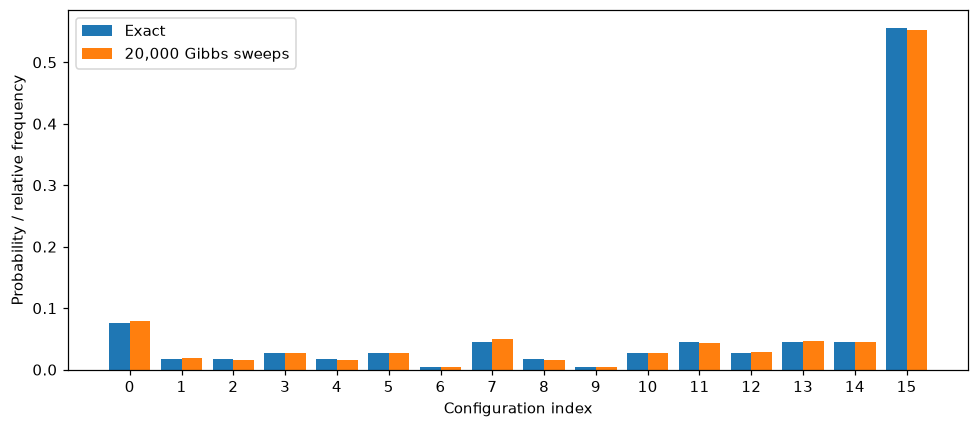

In [8]:
def gibbs_sweep(x: np.ndarray, T: float, h: float,
                rng: np.random.Generator) -> None:
    """Update every spin sequentially in place, with open boundaries."""
    if not np.isfinite(T) or T <= 0:
        raise ValueError('T must be finite and positive.')
    rows, cols = x.shape
    for r in range(rows):
        for c in range(cols):
            neighbor_sum = 0
            if r > 0:
                neighbor_sum += int(x[r - 1, c])
            if r + 1 < rows:
                neighbor_sum += int(x[r + 1, c])
            if c > 0:
                neighbor_sum += int(x[r, c - 1])
            if c + 1 < cols:
                neighbor_sum += int(x[r, c + 1])
            z = 2.0 * (neighbor_sum + h) / T
            q = np.exp(-abs(z))
            p_up = 1.0 / (1.0 + q) if z >= 0 else q / (1.0 + q)
            x[r, c] = 1 if rng.random() < p_up else -1


rng = np.random.default_rng(43)
states_exact, probs_exact = full_distribution(2, T=2.0, h=0.5)
x = rng.choice([-1, 1], size=(2, 2))
for _ in range(1_000):
    gibbs_sweep(x, T=2.0, h=0.5, rng=rng)

n_sweeps = 20_000
recorded_indices = np.empty(n_sweeps, dtype=int)
for step in range(n_sweeps):
    gibbs_sweep(x, T=2.0, h=0.5, rng=rng)
    recorded_indices[step] = state_index(x)
gibbs_frequencies = np.bincount(recorded_indices, minlength=len(probs_exact)) / n_sweeps

print('Index   Exact probability   Gibbs frequency')
for k, (p, f) in enumerate(zip(probs_exact, gibbs_frequencies)):
    print(f'{k:5d}   {p:17.5f}   {f:15.5f}')
print(f'Maximum absolute error: {np.max(np.abs(gibbs_frequencies - probs_exact)):.5f}')
print(f'Total variation distance: {0.5 * np.abs(gibbs_frequencies - probs_exact).sum():.5f}')

plt.figure(figsize=(9, 4))
positions = np.arange(len(probs_exact))
plt.bar(positions - 0.2, probs_exact, width=0.4, label='Exact')
plt.bar(positions + 0.2, gibbs_frequencies, width=0.4, label='20,000 Gibbs sweeps')
plt.xlabel('Configuration index')
plt.ylabel('Probability / relative frequency')
plt.xticks(positions)
plt.legend()
plt.tight_layout()
plt.show()

The cell below runs Gibbs sampling on a $40 \times 40$ grid for several temperatures with $h = 0$. On an infinite grid, the Ising model has a phase transition at the critical temperature $T_c = 2 / \ln(1 + \sqrt{2}) \approx 2.27$. Try temperatures below, around and above $T_c$. What do you observe?

T = 1.50: mean spin = +0.263
T = 2.27: mean spin = +0.030
T = 3.50: mean spin = +0.055


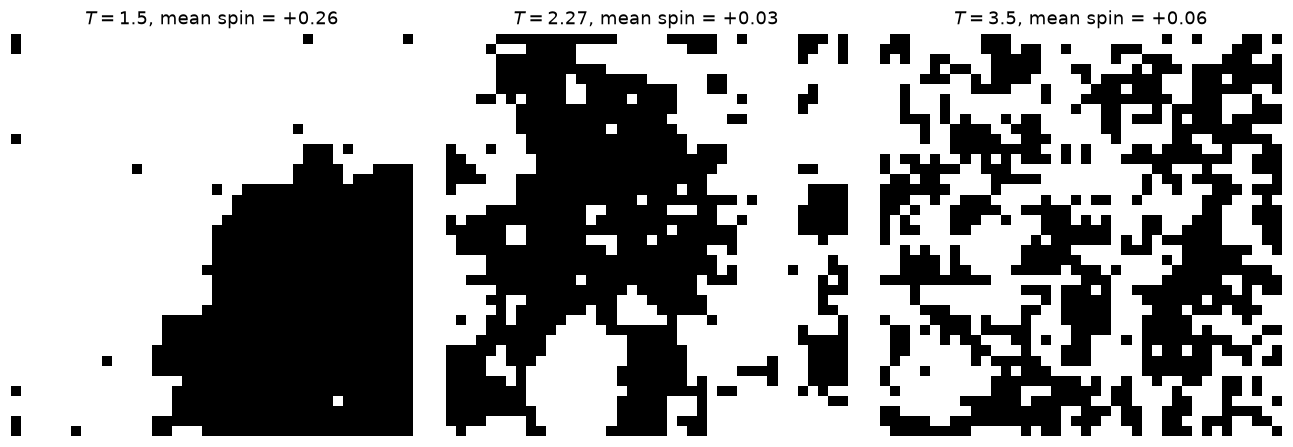

In [9]:
L, h, n_sweeps = 40, 0.0, 300
temperatures = [1.5, 2.27, 3.5]

rng = np.random.default_rng(44)
fig, axes = plt.subplots(1, len(temperatures), figsize=(12, 4))
for ax, T in zip(axes, temperatures):
    x = rng.choice([-1, 1], size=(L, L))
    for _ in range(n_sweeps):
        gibbs_sweep(x, T, h, rng)
    magnetization = x.mean()
    print(f'T = {T:.2f}: mean spin = {magnetization:+.3f}')
    ax.imshow(x, cmap='gray', vmin=-1, vmax=1)
    ax.set_title(f'$T = {T}$, mean spin = {magnetization:+.2f}')
    ax.axis('off')
plt.tight_layout()
plt.show()

#### Interpreting the 40 × 40 grids

White represents +1 and black represents −1. The mean spin
\(m=L^{-2}\sum_i x_i\) measures the imbalance between the two colors.

- **\(T=1.5<T_c\):** agreement is strongly favored. Large regions align,
  and a configuration often has a large absolute mean spin. Starting
  from a random grid, competing domains can persist for many sweeps.
- **\(T\approx2.27\):** expect irregular correlated patches on a range
  of sizes. Local Gibbs sampling relaxes slowly near the critical
  temperature, so 300 sweeps need not establish equilibrium.
- **\(T=3.5>T_c\):** thermal randomness produces a more mixed image
  with smaller patches and typically a mean spin closer to zero.
  Neighbor correlations can still remain; spins are not fully independent.

The quoted \(T_c\) describes an infinite square lattice. A finite 40 × 40
grid shows a smooth crossover, and a single snapshot is illustrative,
not proof of a phase transition or convergence. At zero field, the exact
finite-grid distribution is symmetric under flipping every spin, so
\(\mathbb E[m]=0\) even at low temperature. A single low-temperature sample
can nevertheless have \(m\) close to +1 or −1; switching between these
modes can take a very long time. Repeated runs, longer chains, and traces
of energy and magnetization help assess whether sampling has equilibrated.


**In the saved run:** at T = 1.5, a large black domain survives inside a mostly
white grid (mean spin +0.263), illustrating slow domain relaxation rather than
complete alignment after 300 sweeps. At T = 2.27, the domains are irregular
and the mean spin is +0.030. At T = 3.5, the image is more finely mixed,
with mean spin +0.055. The similar mean spins in the last two images do not
imply similar spatial structure: magnetization alone misses the cluster sizes.
